In [1]:
import os, glob
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
from tqdm import tqdm

plt.rcParams['figure.dpi'] = 300
plt.rcParams['savefig.dpi'] = 300


In [11]:
data_dir = r"D:\!Work\IFA\!data\Urban_fluxes_NE\processed"

cities2test = ['Moscow', 'Tomsk', 'Beijing']
corr_str = {'Tomsk':'new_rot3'}

dfs = {}

for city in cities2test[::-1]:
    files = glob.glob(data_dir + '/' + city + (('_' + corr_str[city]) if city in corr_str else '') + '/*.csv')
    display(files)

    for file in files:
        fname = os.path.basename(file).split('.')[0]
        if 'ERA5' in fname: continue
        if 'Beijing' in fname and '_47m' not in fname and '_80m' not in fname: continue
        df = pd.read_csv(file, parse_dates=[0], index_col=[0])
        dfs[city + '_' + fname] = df

display(dfs.keys())       


['D:\\!Work\\IFA\\!data\\Urban_fluxes_NE\\processed/Beijing\\Beijing_140m.csv',
 'D:\\!Work\\IFA\\!data\\Urban_fluxes_NE\\processed/Beijing\\Beijing_16m.csv',
 'D:\\!Work\\IFA\\!data\\Urban_fluxes_NE\\processed/Beijing\\Beijing_200m.csv',
 'D:\\!Work\\IFA\\!data\\Urban_fluxes_NE\\processed/Beijing\\Beijing_280m.csv',
 'D:\\!Work\\IFA\\!data\\Urban_fluxes_NE\\processed/Beijing\\Beijing_47m.csv',
 'D:\\!Work\\IFA\\!data\\Urban_fluxes_NE\\processed/Beijing\\Beijing_80m.csv',
 'D:\\!Work\\IFA\\!data\\Urban_fluxes_NE\\processed/Beijing\\Beijing_8m.csv',
 'D:\\!Work\\IFA\\!data\\Urban_fluxes_NE\\processed/Beijing\\ERA5.csv',
 'D:\\!Work\\IFA\\!data\\Urban_fluxes_NE\\processed/Beijing\\Xianghe_32m.csv',
 'D:\\!Work\\IFA\\!data\\Urban_fluxes_NE\\processed/Beijing\\Xianghe_80m.csv']

['D:\\!Work\\IFA\\!data\\Urban_fluxes_NE\\processed/Tomsk_new_rot3\\BEK.csv',
 'D:\\!Work\\IFA\\!data\\Urban_fluxes_NE\\processed/Tomsk_new_rot3\\IMCES30m.csv',
 'D:\\!Work\\IFA\\!data\\Urban_fluxes_NE\\processed/Tomsk_new_rot3\\IMCES30m_mezo.csv',
 'D:\\!Work\\IFA\\!data\\Urban_fluxes_NE\\processed/Tomsk_new_rot3\\IMCES40m.csv',
 'D:\\!Work\\IFA\\!data\\Urban_fluxes_NE\\processed/Tomsk_new_rot3\\Oblkom.csv']

['D:\\!Work\\IFA\\!data\\Urban_fluxes_NE\\processed/Moscow\\ERA5.csv',
 'D:\\!Work\\IFA\\!data\\Urban_fluxes_NE\\processed/Moscow\\MSU_11m.csv',
 'D:\\!Work\\IFA\\!data\\Urban_fluxes_NE\\processed/Moscow\\MSU_19m.csv',
 'D:\\!Work\\IFA\\!data\\Urban_fluxes_NE\\processed/Moscow\\MSU_2m.csv',
 'D:\\!Work\\IFA\\!data\\Urban_fluxes_NE\\processed/Moscow\\ZNS_56m.csv']

dict_keys(['Beijing_Beijing_47m', 'Beijing_Beijing_80m', 'Beijing_Xianghe_32m', 'Beijing_Xianghe_80m', 'Tomsk_BEK', 'Tomsk_IMCES30m', 'Tomsk_IMCES30m_mezo', 'Tomsk_IMCES40m', 'Tomsk_Oblkom', 'Moscow_MSU_11m', 'Moscow_MSU_19m', 'Moscow_MSU_2m', 'Moscow_ZNS_56m'])

In [13]:
df_is_ok

,Beijing_Beijing_47m,Beijing_Beijing_80m,Beijing_Xianghe_32m,Beijing_Xianghe_80m,Tomsk_BEK,Tomsk_IMCES30m,Tomsk_IMCES30m_mezo,Tomsk_IMCES40m,Tomsk_Oblkom,Moscow_MSU_11m,Moscow_MSU_19m,Moscow_MSU_2m,Moscow_ZNS_56m
2020-06-30,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.613194,0.613194,0.613194,NaN
2020-07-31,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.000000,1.000000,1.000000,NaN
2020-08-31,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.901882,0.901882,0.901882,NaN
2020-09-30,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.926389,0.922917,0.926389,NaN
2020-10-31,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.999328,0.999328,0.999328,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...
2025-02-28,NaN,NaN,NaN,NaN,0.958829,NaN,0.983631,0.756944,0.993056,NaN,NaN,NaN,0.99749
2025-03-31,NaN,NaN,NaN,NaN,0.970430,NaN,0.973566,0.966846,0.987007,NaN,NaN,NaN,NaN
2025-04-30,NaN,NaN,NaN,NaN,0.975926,NaN,0.977778,0.799074,0.996296,NaN,NaN,NaN,NaN
2025-05-31,NaN,NaN,NaN,NaN,0.995520,NaN,0.998208,0.999104,0.997312,NaN,NaN,NaN,NaN


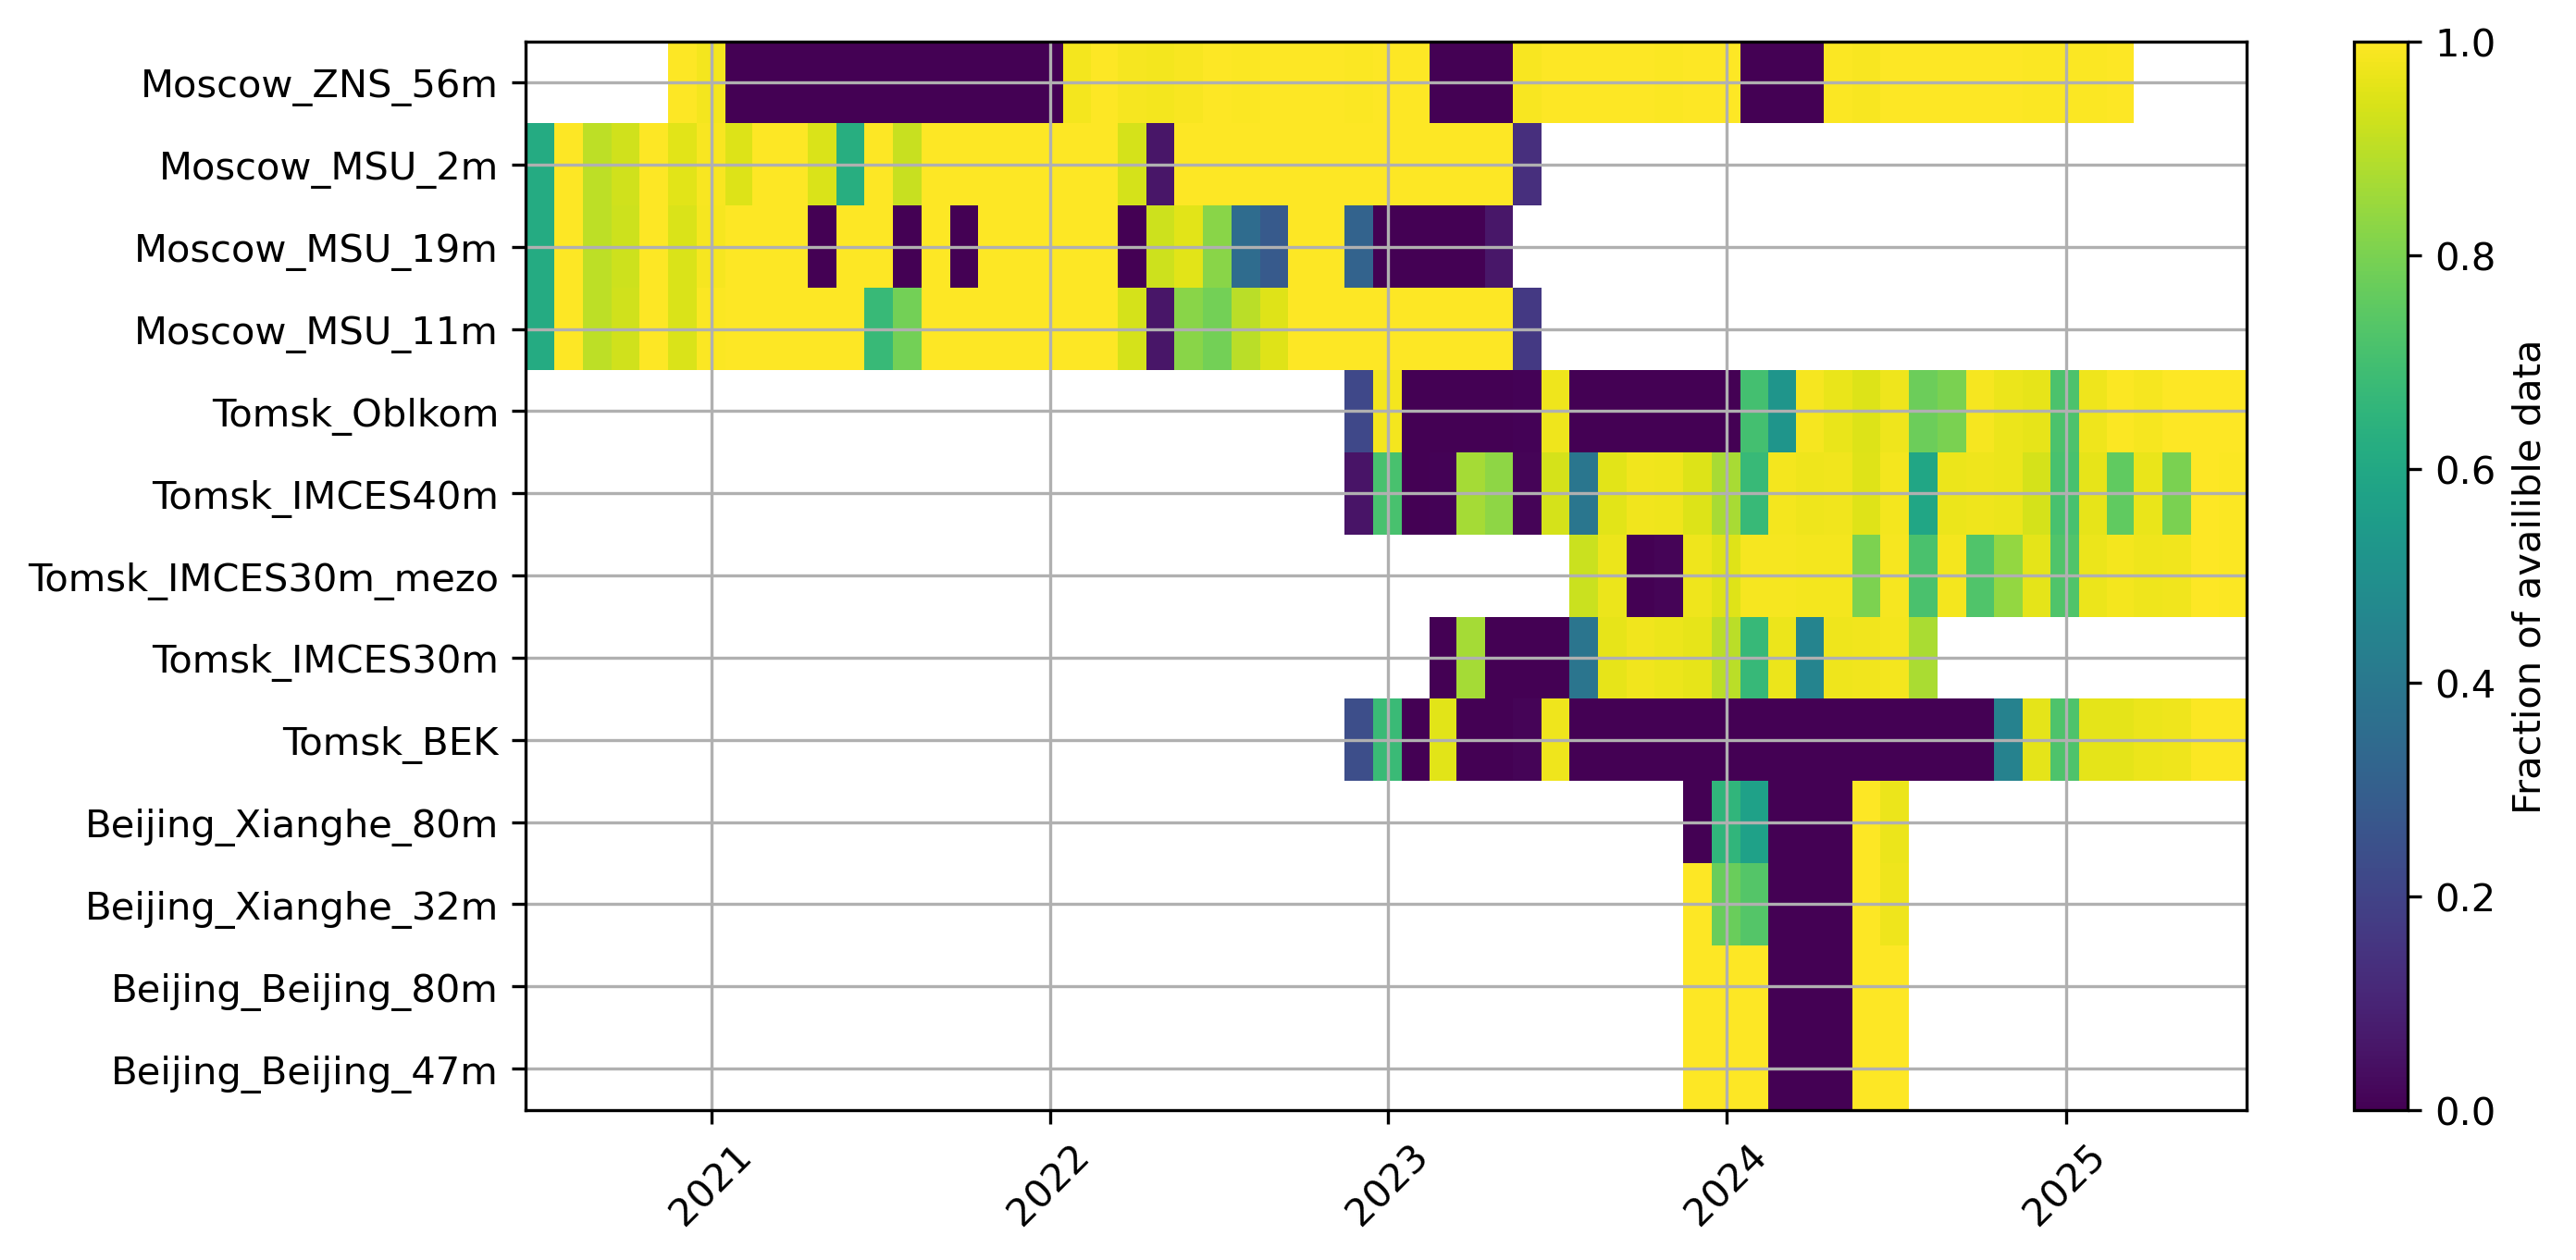

In [14]:
df_is_ok = pd.DataFrame()

for i, site in enumerate (dfs.keys()):
    df4site = dfs[site]
    
    is_ok4site = pd.DataFrame(~np.isnan(df4site['Qh'])).rename(columns = {'Qh': site})
    is_ok4site_dm = is_ok4site.astype(float).fillna(0).resample('ME').mean().fillna(0)    
    df_is_ok = df_is_ok.merge(is_ok4site_dm, how = 'outer', right_index = True, left_index = True)

# display(df_is_ok)

# #data = df_is_ok.astype(float).fillna(0).resample('M').mean()
plt.figure(figsize=(10,5))
plt.pcolormesh(df_is_ok.index, df_is_ok.columns, df_is_ok.T.to_numpy())
plt.grid()
cb = plt.colorbar (location='right')
cb.set_label('Fraction of availible data')
_ = plt.xticks(rotation=45)
